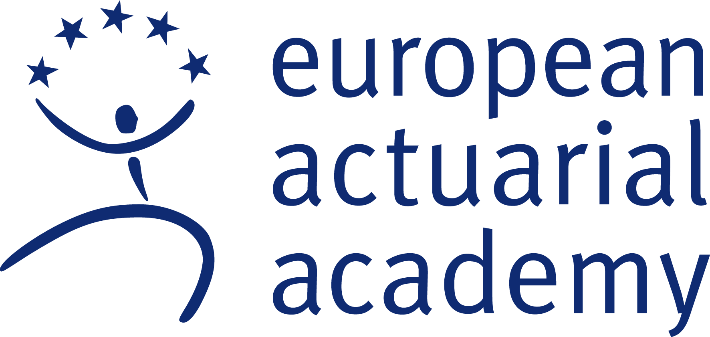

<p style="font-size:17px; text-align:left;"><i>EAA Web Session E0595, GenAI Beyond the Basics: Advanced Concepts for Actuaries, 07 December 2026</i></p>
<p style="font-size:25px; text-align:left; font-weight:bold;">Setup Check: Ready for the Web Session?</p>
<p style="font-size:16px; text-align:left; margin-bottom: 15px;">Dr Simon Hatzesberger<br>Programme slot: before the session (optional) CET</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/simonhatzesberger/genai-beyond-the-basics-20261207/blob/main/notebooks/00_setup_check.ipynb) &nbsp; Notebook `00_setup_check.ipynb` of the repository <https://github.com/simonhatzesberger/genai-beyond-the-basics-20261207>

This short notebook checks whether you can **run** the session notebooks yourself. You do not need it to *follow* the
web session: every notebook is saved with its outputs, so you can read it on GitHub or as HTML (folder `html/` of the
repository) without installing anything.

**Three ways to use the material**

| Option | What you need | Good for |
|---|---|---|
| **Read only** | a web browser | following the session, looking things up later |
| **Google Colab** (recommended for running) | a Google account; an OpenAI API key | running and changing the code without installing anything |
| **Local Python** | Python 3.10 or newer, `pip install -r requirements.txt`; an OpenAI API key | working with your own data and tools |

Click the **Open in Colab** badge above, then choose **Runtime → Run all**. Colab warns that the notebook was not
authored by Google; click **Run anyway**.

<h1 id="api-key"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
1. Your OpenAI API key
</h1>

Calling a model through the API needs an **API key**: a secret that identifies your account and is billed for each
call. You create one at <https://platform.openai.com/api-keys> (a paid account with a small prepaid balance is
enough: running all notebooks of this session once costs well under USD 0.50 at the list prices of November 2026).

**Never paste the key into a notebook cell.** The notebooks look for it in three places, in this order:

1. **Colab Secrets** (in Colab): click the key icon 🔑 in the left sidebar → *Add new secret* → name `OPENAI_API_KEY`,
   paste the key as value, and switch on *Notebook access*.
2. **Environment variable** `OPENAI_API_KEY` (local): in PowerShell `$env:OPENAI_API_KEY = "sk-..."`, on macOS/Linux
   `export OPENAI_API_KEY="sk-..."`, then start Jupyter from the same terminal.
3. **Text file** `openai_api_key.txt` next to the notebooks, containing only the key (never commit or share it).

Company laptops sometimes block Colab or the OpenAI API. In that case, use a private device or simply read the saved
outputs.

In [1]:
# ── Setup: run this cell first ───────────────────────────────────────────────────────────────
import os
import subprocess
import sys
import urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_RAW = "https://raw.githubusercontent.com/simonhatzesberger/genai-beyond-the-basics-20261207/main/notebooks/"


from openai import OpenAI


def load_openai_api_key(name: str = "OPENAI_API_KEY", file_path: str = "openai_api_key.txt") -> str | None:
    """Look for the key in Colab Secrets, then in an environment variable, then in a local text file."""
    try:
        from google.colab import userdata  # only available in Colab
        value = userdata.get(name)
        if value:
            return value.strip()
    except Exception:
        pass
    if os.getenv(name):
        return os.getenv(name).strip()
    for candidate in (Path(file_path), Path("..") / file_path):
        if candidate.exists():
            return candidate.read_text(encoding="utf-8").strip()
    return None


api_key = load_openai_api_key()
client = OpenAI(api_key=api_key or "no-key-found")   # the key's value is never printed

MODEL = "gpt-6-luna"           # OpenAI's current small model (checked 22 Nov 2026: no announced shutdown date)
REASONING = {"effort": "low"}  # always set the reasoning effort explicitly (the default is "medium")

print("Running in", "Google Colab" if IN_COLAB else "a local Python " + sys.version.split()[0])
print("OpenAI API key:", "found" if api_key else "NOT found - you can read the saved outputs, but API calls will fail "
      "(see 00_setup_check.ipynb)")
print("Model:", MODEL, "| reasoning effort:", REASONING["effort"])

Running in a local Python 3.13.1
OpenAI API key: found
Model: gpt-6-luna | reasoning effort: low


<h1 id="environment"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
2. Check the Python environment
</h1>

The next cell lists the packages the notebooks use and whether they can be imported here. Nothing is installed.

In [2]:
import importlib
import importlib.metadata as md_

REQUIRED = {  # import name -> pip package, notebooks that need it
    "openai": ("openai", "all"),
    "pydantic": ("pydantic", "02-06"),
    "pandas": ("pandas", "02-06"),
    "numpy": ("numpy", "05"),
    "requests": ("requests", "05"),
    "pymupdf": ("pymupdf", "05 (installed automatically in Colab)"),
}
OPTIONAL = {
    "ollama": ("ollama", "01, section 3 (local model; needs the Ollama app, not available in Colab)"),
    "torch": ("torch", "04, part B (LoRA fine-tuning)"),
    "transformers": ("transformers", "04, part B"),
    "peft": ("peft", "04, part B"),
    "datasets": ("datasets", "04, part B"),
}

def check(table, label):
    ok = True
    for module, (package, used_in) in table.items():
        try:
            importlib.import_module(module)
            version = md_.version(package)
            print(f"[OK]        {package:<13} {version:<12} used in notebook {used_in}")
        except Exception:
            ok = False
            print(f"[{label}] {package:<13} {'missing':<12} used in notebook {used_in}")
    return ok

print(f"Python {sys.version.split()[0]}\n")
core_ok = check(REQUIRED, "MISSING  ")
print()
_ = check(OPTIONAL, "optional ")

Python 3.13.1

[OK]        openai        3.57.0       used in notebook all
[OK]        pydantic      2.14.4       used in notebook 02-06


[OK]        pandas        3.1.1        used in notebook 02-06
[OK]        numpy         2.5.5        used in notebook 05
[OK]        requests      2.34.2       used in notebook 05
[OK]        pymupdf       2.1          used in notebook 05 (installed automatically in Colab)



[OK]        ollama        0.6.3        used in notebook 01, section 3 (local model; needs the Ollama app, not available in Colab)


[OK]        torch         2.11.0+cpu   used in notebook 04, part B (LoRA fine-tuning)


[OK]        transformers  5.24.0       used in notebook 04, part B


W1122 22:53:13.792000 25984 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


[OK]        peft          0.22.0       used in notebook 04, part B


[OK]        datasets      5.2.0        used in notebook 04, part B


<h1 id="first-call"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
3. One real API call
</h1>

If a key was found, this cell sends one tiny request (a fraction of a cent) and prints the answer.

In [3]:
if api_key:
    try:
        response = client.responses.create(
            model=MODEL,
            reasoning=REASONING,
            input="Reply with exactly: Ready for the EAA web session.",
        )
        print("[OK] The model answered:", response.output_text)
        api_ok = True
    except Exception as exc:
        print("[ATTENTION] The call failed:", type(exc).__name__, str(exc)[:200])
        api_ok = False
else:
    print("[SKIPPED] No key found - see section 1.")
    api_ok = False

[OK] The model answered: Ready for the EAA web session.


<h1 id="ollama"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
4. Optional: a local model with Ollama
</h1>

Section 3 of `01_foundations_best_practices.ipynb` runs a small open-weights model **on your own computer** with
[Ollama](https://ollama.com). This is optional and does not work in Colab. To try it locally: install Ollama, run
`ollama pull qwen3.5:4b` once in a terminal (a download of about 3.4 GB), and keep the Ollama app running.

In [4]:
import json as _json

try:
    with urllib.request.urlopen("http://localhost:11434/api/tags", timeout=3) as r:
        models = [m["name"] for m in _json.load(r)["models"]]
    print("[OK] Ollama is running. Local models:", ", ".join(models) or "none yet")
    if not any(m.startswith("qwen3.5:4b") for m in models):
        print("     Run 'ollama pull qwen3.5:4b' once to get the model used in notebook 01.")
except Exception:
    print("[optional] No Ollama server found on localhost:11434 - fine, notebook 01 then skips the local-model cell.")

[OK] Ollama is running. Local models: qwen3.5:4b


<h1 id="verdict"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
5. Verdict
</h1>

In [5]:
if core_ok and api_ok:
    print("Verdict: your setup is ready to run the session notebooks.")
elif core_ok:
    print("Verdict: packages are fine; add an API key (section 1) to run the notebooks - or simply read the saved outputs.")
else:
    print("Verdict: some packages are missing - run 'pip install -r requirements.txt' (locally) or use Colab.")

Verdict: your setup is ready to run the session notebooks.
